```{index} single: application; airline seating allocation
```
```{index} single: solver; HiGHS
```
```{index} pandas dataframe
```
```{index} single: Pyomo; sets
```
```{index} stochastic optimization
```
```{index} chance constraints
```
```{index} sample average approximation
```
```{index} two-stage problem
```

# 10.1 Aircraft seat allocation problem

## Preamble: Install Pyomo and a solver

The following cell sets and verifies a global SOLVER for the notebook. If run on Google Colab, the cell installs Pyomo and the HiGHS solver, while, if run elsewhere, it assumes Pyomo and HiGHS have been previously installed. It then sets to use HiGHS as solver via the appsi module and a test is performed to verify that it is available. The solver interface is stored in a global object `SOLVER` for later use.

In [1]:
import sys
 
if 'google.colab' in sys.modules:
    %pip install pyomo >/dev/null 2>/dev/null
    %pip install highspy >/dev/null 2>/dev/null

solver = 'appsi_highs'
 
import pyomo.environ as pyo
SOLVER = pyo.SolverFactory(solver)

assert SOLVER.available(), f"Solver {solver} is not available."

## Problem description

An airline is deciding how to partition a new plane for the Amsterdam-Buenos Aires route. This plane can seat 200 economy-class passengers. A section can be created for first-class seats, but each of these seats takes the space of 2 economy-class seats. A business-class section can also be created, but each of these takes the space of 1.5 economy-class seats. The profit for a first-class ticket is three times the profit of an economy ticket, while a business-class ticket has a profit of two times an economy ticket's profit. Once the plane is partitioned into these seating classes, it cannot be changed. 

The airline knows that the plane will not always be full in every section. The airline has initially identified three scenarios to consider with about equal frequency: 

1. Weekday morning and evening traffic;
2. Weekend traffic; and
3. Weekday midday traffic. 

Under Scenario 1 the airline thinks they can sell as many as 20 first-class tickets, 50 business-class tickets, and 200 economy tickets. Under Scenario 2 these figures are 10, 24, and 175, while under Scenario 3, they are 6, 10, and 150, respectively. The following table summarizes the forecast demand for these three scenarios.

<center>

| Scenario | First-class seats | Business-class seats | Economy-class seats |
| :-- | :-: | :-: | :-: |
| (1) weekday morning and evening | 20 | 50 | 200 |
| (2) weekend | 10 | 24 | 175 |
| (3) weekday midday | 6 | 10 | 150 |
| **Average Scenario** | **12** | **28** | **175** |

</center>

The goal of the airline is to maximize ticket revenue. For marketing purposes, the airline will not sell more tickets than seats in each of the sections (hence no overbooking strategy). We further assume customers seeking a first-class or business-class seat will not downgrade if those seats are unavailable.

### Attribution

This problem statement is adapted from an exercise and examples presented in the following book: 

* *Birge, J. R., & Louveaux, F. (2011). Introduction to stochastic programming. Springer Science & Business Media.*

The adaptations include a change to parameters for consistency among reformulations of the problem, and additional treatments for sample average approximation (SAA) with chance constraints.

## Problem data

Pandas DataFrames and Series are used to encode problem data in the following cell, and to encode problem solutions in subsequent cells.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# scenario data
demand = pd.DataFrame(
    {
        "morning and evening": {"F": 20, "B": 50, "E": 200},
        "weekend": {"F": 10, "B": 24, "E": 175},
        "midday": {"F": 6, "B": 10, "E": 150},
    }
).T

# global revenue and seat factor data
capacity = 200
revenue_factor = pd.Series({"F": 3.0, "B": 2.0, "E": 1.0})
seat_factor = pd.Series({"F": 2.0, "B": 1.5, "E": 1.0})

## Analytics

Prior to optimization, a useful first step is to prepare an analytics function to display performance for any given allocation of seats. The first-stage decision variables are the number of seats allocated for each class $c\in C$. We would like to provide an analysis showing the operational consequences for any proposed allocation of seats. For this purpose, we create a function ``seat_report()`` that shows the tickets that can be sold in each scenario, the resulting revenue, and the unsatisfied demand ('spillage'). 

To establish a basis for analyzing possible solutions to the airline's problem, this function first is demonstrated for the case where the airplane is configured as entirely economy-class.


Seat Allocation


,F,B,E,TOTAL
seat allocation,0.0,0.0,200.0,200.0
economy equivalent seat allocation,0.0,0.0,200.0,200.0



Tickets Sold


,F,B,E
morning and evening,0,0,200
weekend,0,0,175
midday,0,0,150



Seats not Sold


,F,B,E
morning and evening,0,0,0
weekend,0,0,25
midday,0,0,50



Spillage (Unfulfilled Demand)


,F,B,E
morning and evening,20,50,0
weekend,10,24,0
midday,6,10,0



Expected Revenue (in units of economy ticket price): 175.00


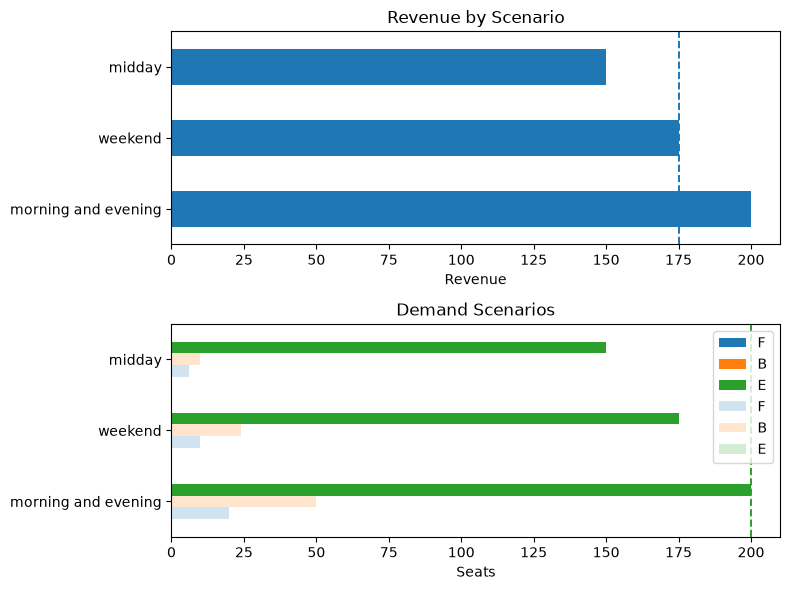

In [3]:
# function to report analytics for any given seat allocations
def seat_report(seats, demand, name=""):
    classes = seats.index

    # report seat allocation
    equivalent_seats = pd.DataFrame(
        {
            "seat allocation": {c: seats[c] for c in classes},
            "economy equivalent seat allocation": {
                c: seats[c] * seat_factor[c] for c in classes
            },
        }
    ).T
    equivalent_seats["TOTAL"] = equivalent_seats.sum(axis=1)
    print("\nSeat Allocation")
    display(equivalent_seats)

    # tickets sold is the minimum of available seats and demand
    tickets = pd.DataFrame()
    for c in classes:
        tickets[c] = np.minimum(seats[c], demand[c])
    print("\nTickets Sold")
    display(tickets)

    # seats unsold
    unsold = pd.DataFrame()
    for c in classes:
        unsold[c] = seats[c] - tickets[c]
    print("\nSeats not Sold")
    display(unsold)

    # spillage (unmet demand)
    spillage = demand - tickets
    print("\nSpillage (Unfulfilled Demand)")
    display(spillage)

    # compute revenue
    revenue = tickets.dot(revenue_factor)
    print(
        f"\nExpected Revenue (in units of economy ticket price): {revenue.mean():.2f}"
    )

    # charts
    fig, ax = plt.subplots(2, 1, figsize=(8, 6))
    revenue.plot(ax=ax[0], kind="barh", title="Revenue by Scenario")
    ax[0].plot([revenue.mean()] * 2, ax[0].get_ylim(), "--", lw=1.4)
    ax[0].set_xlabel("Revenue")

    tickets[classes].plot(
        ax=ax[1], kind="barh", rot=0, stacked=False, title="Demand Scenarios"
    )
    demand[classes].plot(
        ax=ax[1],
        kind="barh",
        rot=0,
        stacked=False,
        title="Demand Scenarios",
        alpha=0.2,
    )
    for c in classes:
        ax[1].plot([seats[c]] * 2, ax[1].get_ylim(), "--", lw=1.4)
    ax[1].set_xlabel("Seats")
    fig.tight_layout()
    return None


# trivial solution (all seats in economy) and report
seats_all_economy = pd.Series({"F": 0, "B": 0, "E": 200})
seat_report(seats_all_economy, demand)

## Model 1. Deterministic solution for the average demand scenario

A common starting point in stochastic optimization is to solve the deterministic problem where future demands are fixed at their mean values and compute the corresponding optimal solution. Evaluating the resulting allocation under the original demand scenarios gives the *expectation of the expected value problem (EEV)*, also called the *expected value of the mean (EVM)* solution.

Let us introduce the set $C$ of the three possible classes, i.e., $C=\{F,B,E\}$. The objective function is to maximize ticket revenue.

$$
\max_{s_c, t_c} \quad \sum_{c\in C} r_c t_c 
$$

where $r_c$ is the revenue from selling a ticket for a seat in class $c\in C$.

Let $s_c$ denote the number of seats of class $c \in C$ installed in the new plane. Let $f_c$ be the scale factor denoting the number of economy seats displaced by one seat in class $c \in C$. Then, since there is a total of 200 economy-class seats that could fit on the plane, the capacity constraint reads as

$$
    \sum_{c\in C} f_c s_c \leq 200,
$$

Let $\mu_c$ be the mean demand for seats of class $c\in C$, and let $t_c$ be the number of tickets of class $c\in C$ that are sold. To ensure we do not sell more tickets than available seats nor more than demand, we need to add two more constraints:

$$
\begin{align*}
    t_c & \leq s_c \qquad \forall \, c\in C \\
    t_c & \leq \mu_c \qquad \forall \, c\in C
\end{align*}
$$

Lastly, both ticket and seat variables need to be nonnegative integers, so we add the constraints $\boldsymbol{t}, \boldsymbol{s} \in \mathbb{Z}_+$. 

The following cell presents a Pyomo model implementing this model.


Seat Allocation


,F,B,E,TOTAL
seat allocation,12.0,28.0,134.0,174.0
economy equivalent seat allocation,24.0,42.0,134.0,200.0



Tickets Sold


,F,B,E
morning and evening,12.0,28.0,134.0
weekend,10.0,24.0,134.0
midday,6.0,10.0,134.0



Seats not Sold


,F,B,E
morning and evening,0.0,0.0,0.0
weekend,2.0,4.0,0.0
midday,6.0,18.0,0.0



Spillage (Unfulfilled Demand)


,F,B,E
morning and evening,8.0,22.0,66.0
weekend,0.0,0.0,41.0
midday,0.0,0.0,16.0



Expected Revenue (in units of economy ticket price): 203.33


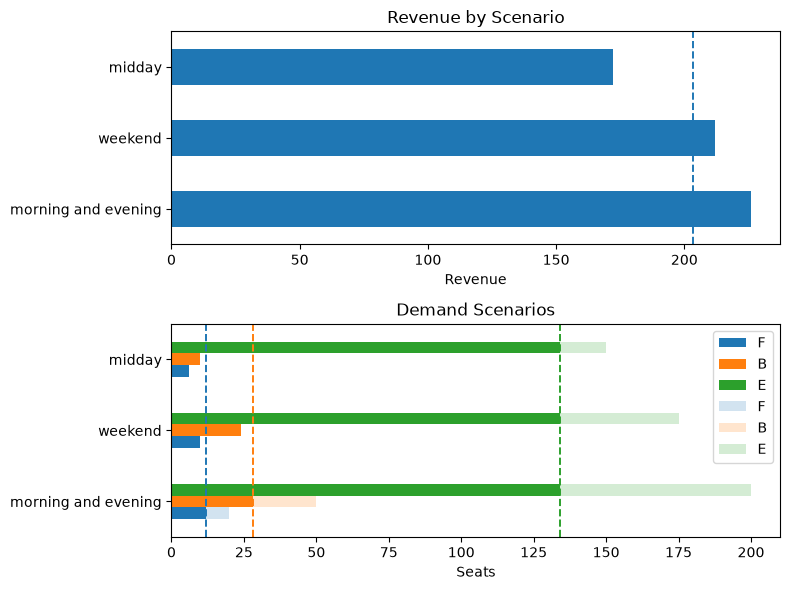

In [4]:
def aircraft_deterministic(demand):
    m = pyo.ConcreteModel("Aircraft seat allocation - Deterministic")

    m.CLASSES = pyo.Set(initialize=demand.columns)

    # first stage variables and constraints
    m.seats = pyo.Var(m.CLASSES, domain=pyo.NonNegativeIntegers)

    @m.Constraint()
    def plane_seats(m):
        return sum(m.seats[c] * seat_factor[c] for c in m.CLASSES) <= capacity

    # second stage variable and constraints
    m.tickets = pyo.Var(m.CLASSES, domain=pyo.NonNegativeIntegers)

    @m.Constraint(m.CLASSES)
    def demand_limits(m, c):
        return m.tickets[c] <= demand[c].mean()

    @m.Constraint(m.CLASSES)
    def seat_limits(m, c):
        return m.tickets[c] <= m.seats[c]

    # objective
    @m.Objective(sense=pyo.maximize)
    def revenue(m):
        return sum(m.tickets[c] * revenue_factor[c] for c in m.CLASSES)

    return m


# Solve the mean-value model; seat_report evaluates its allocation on the scenarios (EEV)
model_eev = aircraft_deterministic(demand)
results = SOLVER.solve(model_eev)
pyo.assert_optimal_termination(results)
seats_eev = pd.Series({c: model_eev.seats[c]() for c in model_eev.CLASSES})
seat_report(seats_eev, demand)

## Model 2. Two-stage stochastic optimization and its extensive form

If we assume demand is not certain, we can formulate a two-stage stochastic optimization problem. The first-stage or here-and-now variables are the $s_c$'s, those related to the seat allocations. Due to their dependence on the realized demand $\boldsymbol{z}$, the variables $t_c$'s describing the number of tickets sold are second-stage or recourse decision variables. The full problem formulation is as follows: the first stage problem is

$$
\begin{align*}
    \max \quad & \mathbb E_{z} Q(\boldsymbol{s},\boldsymbol{z}) \\
    \text{s.t.} \quad & \sum_{c\in C} f_c s_c \leq 200,\\
    & \boldsymbol{s} \in \mathbb{Z}_+,
\end{align*}
$$

where $Q(\boldsymbol{s},\boldsymbol{z})$ is the value of the second-stage problem, defined as

$$
\begin{align*}
    Q(\boldsymbol{s},\boldsymbol{z}) := \max \quad & \sum_{c\in C} r_c t_{c}\\
    \text{s.t.} \quad 
    & t_c \leq s_c & \forall \, c\in C \\
    & t_c \leq z_c & \forall \, c\in C \\
    & \boldsymbol{t} \in \mathbb{Z}_+.
\end{align*}
$$

In view of the assumption that there is only a finite number $N=|S|$ of scenarios for ticket demand, we can write the extensive form of the two-stage stochastic optimization problem above and solve it exactly. To do so, we modify the second-stage variables $t_{c,s}$ so that they are indexed by both class $c$ and scenario $s$. The expectation can thus be replaced with the average revenue over the $N$ scenarios, that is

$$
\max \quad \sum_{s \in S} \frac{1}{N} \sum_{c\in C}  r_c t_{c, s},
$$

where the fraction $\frac{1}{N}$ appears since we assume that all $N$ scenarios are equally likely. The first stage constraint remains unchanged, while the second stage constraints are duplicated for each scenario $s \in S$, namely

$$
\begin{align*}
t_{c,s} & \leq s_c & \forall \, (c,s)\in C\times S \\
t_{c,s} & \leq z_{c, s} & \forall \, (c, s) \in C \times S
\end{align*}
$$

The following cell presents a Pyomo model implementing this model and solving it for the $N=3$ equiprobable scenarios introduced above.


Seat Allocation


,F,B,E,TOTAL
seat allocation,10.0,20.0,150.0,180.0
economy equivalent seat allocation,20.0,30.0,150.0,200.0



Tickets Sold


,F,B,E
morning and evening,10.0,20.0,150.0
weekend,10.0,20.0,150.0
midday,6.0,10.0,150.0



Seats not Sold


,F,B,E
morning and evening,0.0,0.0,0.0
weekend,0.0,0.0,0.0
midday,4.0,10.0,0.0



Spillage (Unfulfilled Demand)


,F,B,E
morning and evening,10.0,30.0,50.0
weekend,0.0,4.0,25.0
midday,0.0,0.0,0.0



Expected Revenue (in units of economy ticket price): 209.33


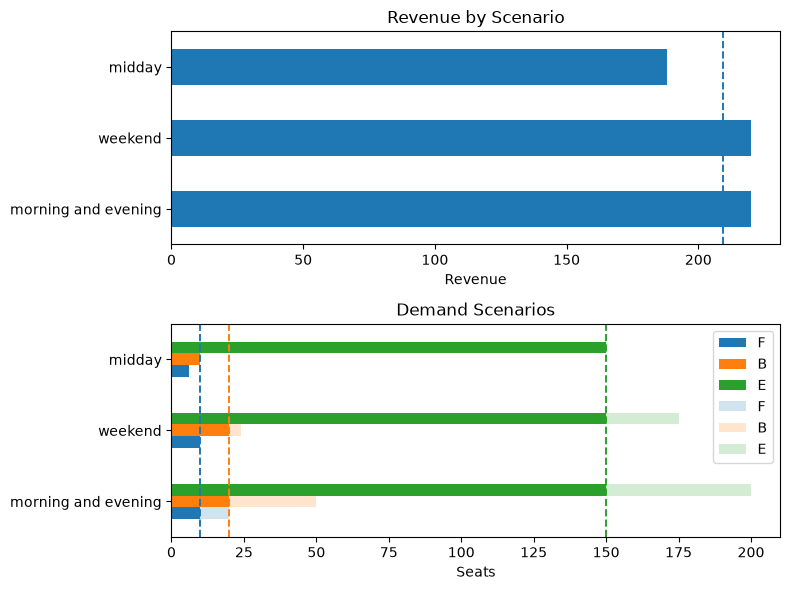

In [5]:
def aircraft_stochastic(demand):
    m = pyo.ConcreteModel("Aircraft seat allocation - Demand scenarios")

    m.CLASSES = pyo.Set(initialize=demand.columns)
    m.SCENARIOS = pyo.Set(initialize=demand.index)

    # first stage variables and constraints
    m.seats = pyo.Var(m.CLASSES, domain=pyo.NonNegativeIntegers)

    @m.Constraint()
    def plane_seats(m):
        return sum(m.seats[c] * seat_factor[c] for c in m.CLASSES) <= capacity

    # second stage variable and constraints
    m.tickets = pyo.Var(m.CLASSES, m.SCENARIOS, domain=pyo.NonNegativeIntegers)

    @m.Constraint(m.CLASSES, m.SCENARIOS)
    def demand_limits(m, c, s):
        return m.tickets[c, s] <= demand[c][s]

    @m.Constraint(m.CLASSES, m.SCENARIOS)
    def seat_limits(m, c, s):
        return m.tickets[c, s] <= m.seats[c]

    # objective
    @m.Objective(sense=pyo.maximize)
    def revenue(m):
        return sum(
            m.tickets[c, s] * revenue_factor[c] for c in m.CLASSES for s in m.SCENARIOS
        ) / len(m.SCENARIOS)

    return m


# create and solve model for the three scenarios defined above
model_stochastic = aircraft_stochastic(demand)
results = SOLVER.solve(model_stochastic)
pyo.assert_optimal_termination(results)
seats_stochastic = pd.Series(
    {c: model_stochastic.seats[c]() for c in model_stochastic.CLASSES}
)
seat_report(seats_stochastic, demand)

## Model 3. Adding chance constraints

The airline wishes a special guarantee for its clients enrolled in its loyalty program. In particular, it wants $98\%$ probability to cover the demand of first-class seats and $95\%$ probability that first- and business-class seats together cover the combined first- and business-class demand of loyalty-program clients. First-class passengers are covered if they can purchase a first-class seat. Business-class passengers are covered if they purchase a business-class seat or upgrade to a first-class seat. Upgrades enter only this service requirement; the revenue recourse still sells tickets within each class and does not sell unused first-class seats to business passengers. 

Assume the demand of loyalty-program passengers is normally distributed as $z_F \sim \mathcal N(\mu_F, \sigma_F^2)$ and $z_B \sim \mathcal N(\mu_B, \sigma_B^2)$ for first-class and business, respectively, where the parameters are given in the table below. For completeness, we also include the parameters for economy-class passengers.

<center>

| | $\mu_{\cdot}$ | $\sigma_{\cdot}$ |
| :--: | :--: | :--: |
| F | 12 | 4 |
| B | 28 | 8 |
| E | 175 | 20 |

</center>

We further assume that the demands for first-class and business-class seats are independent of each other and of the scenario (time of the week).

Let $s_F$ be the number of first-class seats and $s_B$ the number of business seats. The probabilistic constraints are

$$
\mathbb P(s_F \geq z_F ) \geq 0.98, \qquad \text{ and } \qquad \mathbb P(s_F + s_B \geq z_F + z_B ) \geq 0.95.
$$

These can be written equivalently as linear constraints, specifically 

$$
\frac{s_F - \mu_F}{\sigma_F} \geq \Phi^{-1}(0.98) \approx 2.054 \qquad \text{ and } \qquad \frac{(s_F + s_B) - (\mu_F + \mu_B)}{\sqrt{\sigma_F^2 + \sigma_B^2}} \geq \Phi^{-1}(0.95) \approx 1.645.
$$

For the second constraint, we use the fact that the sum of the two independent random variables $z_F$ and $z_B$ is normally distributed with mean $\mu_F + \mu_B$ and variance $\sigma_F^2 + \sigma_B^2$. 

We add these equivalent linear counterparts of the two chance constraints to the stochastic optimization model. Rather than writing a function to create a whole new model, we can use the prior function to create and add the two chance constraints using decorators.


Seat Allocation


,F,B,E,TOTAL
seat allocation,21.0,34.0,107.0,162.0
economy equivalent seat allocation,42.0,51.0,107.0,200.0



Tickets Sold


,F,B,E
morning and evening,20.0,34.0,107.0
weekend,10.0,24.0,107.0
midday,6.0,10.0,107.0



Seats not Sold


,F,B,E
morning and evening,1.0,0.0,0.0
weekend,11.0,10.0,0.0
midday,15.0,24.0,0.0



Spillage (Unfulfilled Demand)


,F,B,E
morning and evening,0.0,16.0,93.0
weekend,0.0,0.0,68.0
midday,0.0,0.0,43.0



Expected Revenue (in units of economy ticket price): 188.33


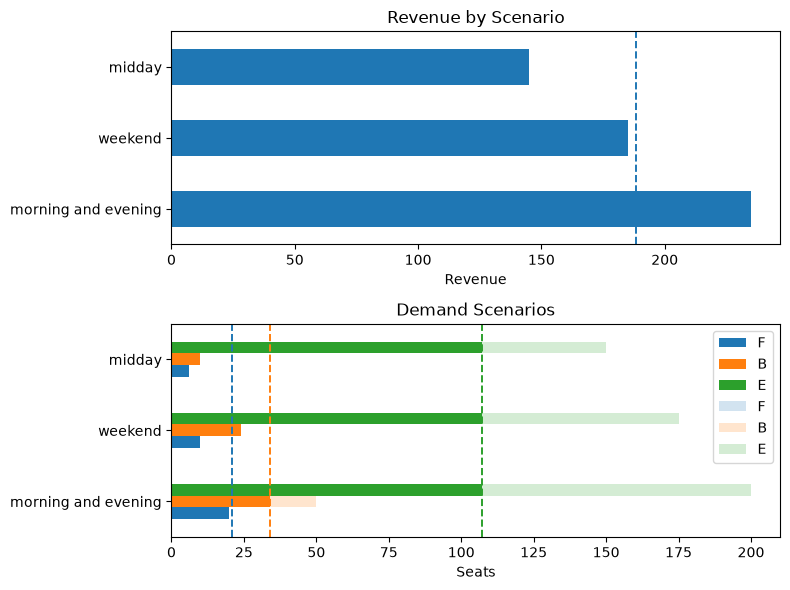

In [6]:
# define the mean and standard deviation of the demand for each class
mu = demand.mean()
sigma = {"F": 4, "B": 8, "E": 20}


def aircraft_cc(demand, QoSF=0.98, QoSFB=0.95):
    # create two-stage stochastic model as before
    m = aircraft_stochastic(demand)

    # add equivalent counterparts of the two chance constraints to the first stage problem
    # the coefficients related the inverse CDF of the standard normal are computed using the norm.ppf function
    @m.Constraint()
    def first_class(m):
        return (m.seats["F"] - mu["F"]) >= norm.ppf(QoSF) * sigma["F"]

    @m.Constraint()
    def business_class(m):
        return m.seats["F"] + m.seats["B"] - (mu["F"] + mu["B"]) >= norm.ppf(
            QoSFB
        ) * np.sqrt(sigma["F"] ** 2 + sigma["B"] ** 2)

    return m


# create and solve model
model_cc = aircraft_cc(demand)
results = SOLVER.solve(model_cc)
pyo.assert_optimal_termination(results)
seats_cc = pd.Series({c: model_cc.seats[c]() for c in model_cc.CLASSES})
seat_report(seats_cc, demand)

## Model 4. Solving the case of continuous demand distributions using the SAA method 

Let us now move past the simplifying assumption that there are only three equally likely scenarios and consider the case where the demand is described by a random vector $(z_F, z_B, z_E)$, where $z_c$ is the demand for seats of class $c\in C$. The demand for class $c$ is assumed to be independent and normally distributed with mean $\mu_c$ and variance $\sigma_c^2$ as reported in the following table

<center>

| | $\mu$ | $\sigma$ |
| :--: | :--: | :--: |
| F | 12 | 4 |
| B | 28 | 8 |
| E | 175 | 20 |

</center>

Note that we model the demand for each class using a continuous random variable, which is a simplification of the real world, where the ticket demand is always a discrete nonnegative number. Therefore, we round the sampled demands to the nearest integer and replace negative values by zero.

We now use SAA to approximate the expected revenue rather than enumerate demand scenarios. The first step of the SAA is to generate a collection of $N$ scenarios $(z_{F,s}, z_{B,s}, z_{E,s})$ for $s=1,\ldots,N$. We can do this by sampling from the normal distributions with the given means and variances. 

For the sake of generality, we create a script to generate scenarios in which the three demands have a general correlation structure captured by a correlation matrix $\boldsymbol{\rho}$.

### Scenario generation (uncorrelated case)

We use a fixed seed and `method="cholesky"` in both sampling cells. Cholesky factorization avoids the singular-vector sign and basis choices of the default SVD method, making this seeded example more reproducible across numerical-library builds. Keep the class order, seed and sampling method fixed to reproduce the values shown here.


Model Covariance


,F,B,E
F,16,0,0
B,0,64,0
E,0,0,400


,mu (mean),sample mean,sigma (std),sample std
F,12.0,11.577,4,3.975409
B,28.0,28.220,8,7.707724
E,175.0,174.416,20,20.433318


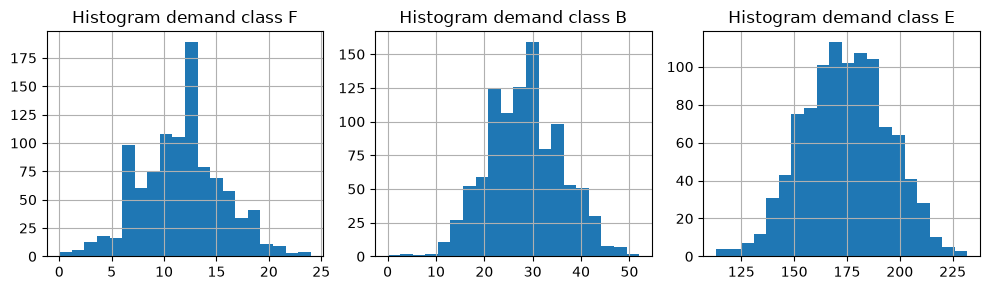

In [7]:
# sample size
N = 1000

# define the mean mu and standard deviation sigma of the demand for each class
mu = demand.mean()
sigma = {"F": 4, "B": 8, "E": 20}
classes = demand.columns

# build covariance matrix from covariances and correlations
s = np.array(list(sigma.values()))
S = np.diag(s) @ np.diag(s)
print("\nModel Covariance")
df = pd.DataFrame(S, index=classes, columns=classes)
display(df)

# generate N samples, round each demand entry to nearest integer, and replace negative values by zero
seed = 0
rng = np.random.default_rng(seed)
samples = rng.multivariate_normal(list(mu), S, N, method="cholesky").round()
demand_saa = pd.DataFrame(samples, columns=classes)
demand_saa[demand_saa < 0] = 0

# report sample means and standard deviations for each class
demand_saa_stats = pd.DataFrame(
    {
        "mu (mean)": mu,
        "sample mean": demand_saa.mean(),
        "sigma (std)": sigma,
        "sample std": demand_saa.std(),
    }
)
display(demand_saa_stats)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
for i, ci in enumerate(classes):
    demand_saa[ci].hist(ax=ax[i], bins=20)
    ax[i].set_title(f"Histogram demand class {ci}")
fig.tight_layout()

We also introduce a new function to report the solution and its features in this more general continuous demand case.

In [8]:
# function to report analytics for SAA case
def seat_report_saa(seats, demand):
    classes = seats.index

    # report seat allocation
    equivalent_seats = pd.DataFrame(
        {
            "seat allocation": {c: seats[c] for c in classes},
            "economy equivalent seat allocation": {
                c: seats[c] * seat_factor[c] for c in classes
            },
        }
    ).T
    equivalent_seats["TOTAL"] = equivalent_seats.sum(axis=1)
    print("\nSeat Allocation")
    display(equivalent_seats)

    # tickets sold
    tickets = pd.DataFrame()
    for c in classes:
        tickets[c] = np.minimum(seats[c], demand[c])

    print("\nMean Tickets Sold")
    display(tickets.mean())

    # seats unsold
    unsold = pd.DataFrame()
    for c in classes:
        unsold[c] = seats[c] - tickets[c]
    print("\nMean Seats not Sold")
    display(unsold.mean())

    # spillage (unmet demand)
    spillage = demand - tickets
    print("\nMean Spillage (Unfulfilled Demand)")
    display(spillage.mean())

    # compute revenue
    revenue = tickets.dot(revenue_factor)
    print(
        f"\nExpected Revenue (in units of economy ticket price): {revenue.mean():.2f}"
    )

    # charts
    fig, ax = plt.subplots(1, 1, figsize=(8, 4))
    revenue.hist(ax=ax, bins=20)
    ax.set_title("Revenue Histogram")

    fig, ax = plt.subplots(1, 3, figsize=(12, 3))
    for i, c in enumerate(classes):
        xmax = 1.05 * max(1, demand[c].max(), seats[c])
        bins = np.linspace(0, xmax, 31)
        tickets[c].hist(ax=ax[i], bins=bins, alpha=0.4)
        demand[c].hist(ax=ax[i], bins=bins, alpha=0.4)
        ax[i].legend(["Tickets Sold", "Demand"])
        ax[i].set_xlim(0, xmax)
        ax[i].set_title(f"Class {c}")
        ax[i].set_xlabel("Tickets or demand")
        ax[i].set_ylabel("Scenarios")

    fig.tight_layout()
    return None

We can now solve the stochastic optimization problem using the generated $N=1000$ scenarios. Note that we can use the previously defined function ``aircraft_stochastic`` to solve the model by simply calling it with a different dataframe as argument.


Seat Allocation


,F,B,E,TOTAL
seat allocation,10.0,24.0,144.0,178.0
economy equivalent seat allocation,20.0,36.0,144.0,200.0



Mean Tickets Sold


F      9.106
B     22.637
E    143.423
dtype: float64


Mean Seats not Sold


F    0.894
B    1.363
E    0.577
dtype: float64


Mean Spillage (Unfulfilled Demand)


F     2.471
B     5.583
E    30.993
dtype: float64


Expected Revenue (in units of economy ticket price): 216.01


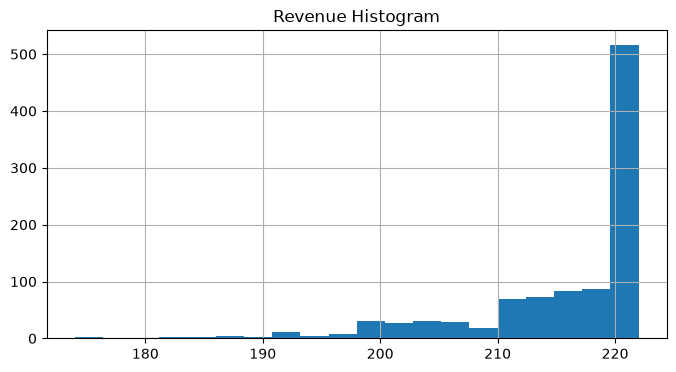

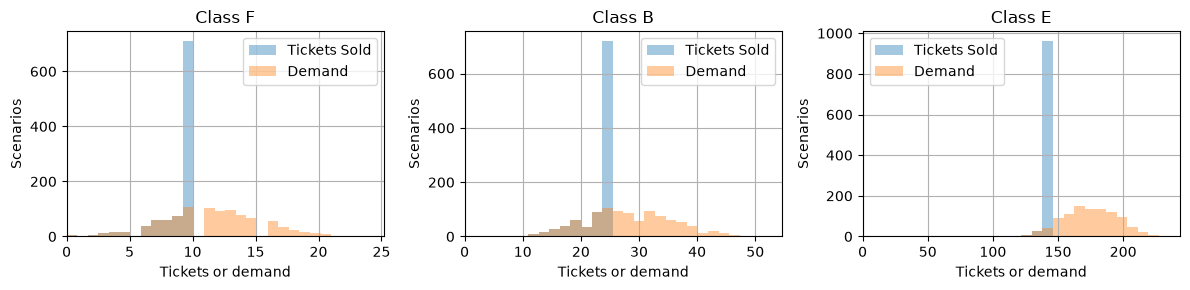

In [9]:
model_saa = aircraft_stochastic(demand_saa)
results = SOLVER.solve(model_saa)
pyo.assert_optimal_termination(results)
seats_saa = pd.Series({c: model_saa.seats[c]() for c in model_saa.CLASSES})
seat_report_saa(seats_saa, demand_saa)

## Model 5. Adding correlations between different demand types

Now assume the ticket demand for the three categories is captured by a $3$-dimensional multivariate normal distribution with mean $\mu=(\mu_F, \mu_B, \mu_E)$, variances $(\sigma_F^2, \sigma_B^2, \sigma_E^2)$ and a symmetric correlation matrix 

$$
P = \left(
\begin{array}{ccc}
1 & \rho_{FB} & \rho_{FE} \\
\rho_{BF} & 1 & \rho_{BE}\\
\rho_{EF} & \rho_{EB} & 1 \\
\end{array}
\right)
$$

The covariance matrix is given by $\Sigma = \text{diag}(\sigma)\ P\ \text{diag}(\sigma)$ or

$$
\Sigma= \left(
\begin{array}{ccc}
 \sigma_F^2 & \rho_{FB}\sigma_F\sigma_B & \rho_{FE}\sigma_F\sigma_E \\
\rho_{BF}\sigma_B\sigma_F & \sigma_B^2 & \rho_{BE}\sigma_B\sigma_E\\
\rho_{EF}\sigma_E\sigma_F & \rho_{EB}\sigma_E\sigma_B & \sigma_E^2 \\
\end{array}
\right)
$$

We assume $\rho_{FB} = 0.6$, $\rho_{BE} = 0.4$ and $\rho_{FE} = 0.2$.
 
We now sample $N=1000$ scenarios from this multivariate correlated normal distribution and use the SAA method to approximate the solution of the two-stage stochastic optimization problem.

,mu,sigma
F,12.0,4
B,28.0,8
E,175.0,20


,mu,sample means
F,12.0,11.577
B,28.0,27.677
E,175.0,174.271


,sigma,sample std dev
F,4,3.975409
B,8,7.755567
E,20,20.133975



Model Covariance


,F,B,E
F,16.0,19.2,16.0
B,19.2,64.0,64.0
E,16.0,64.0,400.0



Sample Covariance


,F,B,E
F,15.803875,18.627999,14.976610
B,18.627999,60.148820,57.563096
E,14.976610,57.563096,405.376936


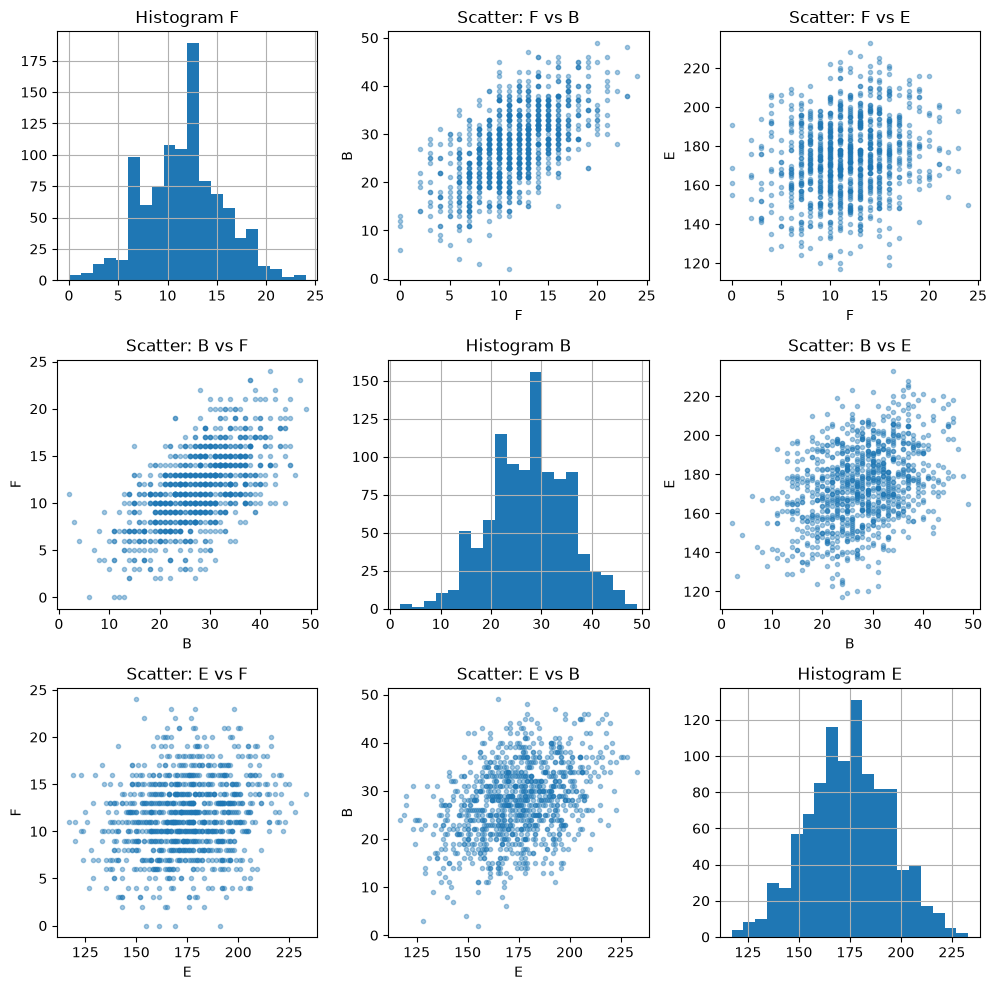

In [10]:
# sample size
N = 1000

# define the mean mu and standard deviation sigma of the demand for each class
mu = demand.mean()
sigma = {"F": 4, "B": 8, "E": 20}
classes = demand.columns
display(pd.DataFrame({"mu": mu, "sigma": sigma}))

# correlation matrix
P = np.array([[1, 0.6, 0.2], [0.6, 1, 0.4], [0.2, 0.4, 1]])

# build covariance matrix from covariances and correlations
s = np.array(list(sigma.values()))
S = np.diag(s) @ P @ np.diag(s)

# generate N samples, round each demand entry to nearest integer, and replace negative values by zero
seed = 0
rng = np.random.default_rng(seed)
samples = rng.multivariate_normal(list(mu), S, N, method="cholesky").round()
demand_saa = pd.DataFrame(samples, columns=classes)
demand_saa[demand_saa < 0] = 0

df = pd.DataFrame(mu, columns=["mu"])
df["sample means"] = demand_saa.mean()
display(df)

df = pd.DataFrame(pd.Series(sigma), columns=["sigma"])
df["sample std dev"] = demand_saa.std()
display(df)

print("\nModel Covariance")
df = pd.DataFrame(S, index=classes, columns=classes)
display(df)

print("\nSample Covariance")
display(pd.DataFrame(demand_saa.cov()))

fig, ax = plt.subplots(3, 3, figsize=(10, 10))
for i, ci in enumerate(classes):
    for j, cj in enumerate(classes):
        if i == j:
            demand_saa[ci].hist(ax=ax[i, i], bins=20)
            ax[i, i].set_title(f"Histogram {ci}")
        else:
            ax[i, j].plot(demand_saa[ci], demand_saa[cj], ".", alpha=0.4)
            ax[i, j].set_xlabel(ci)
            ax[i, j].set_ylabel(cj)
            ax[i, j].set_title(f"Scatter: {ci} vs {cj}")
fig.tight_layout()


Seat Allocation


,F,B,E,TOTAL
seat allocation,10.0,24.0,144.0,178.0
economy equivalent seat allocation,20.0,36.0,144.0,200.0



Mean Tickets Sold


F      9.106
B     22.373
E    143.402
dtype: float64


Mean Seats not Sold


F    0.894
B    1.627
E    0.598
dtype: float64


Mean Spillage (Unfulfilled Demand)


F     2.471
B     5.304
E    30.869
dtype: float64


Expected Revenue (in units of economy ticket price): 215.47


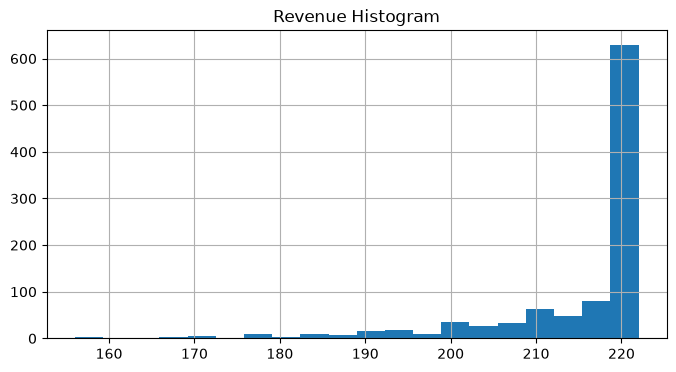

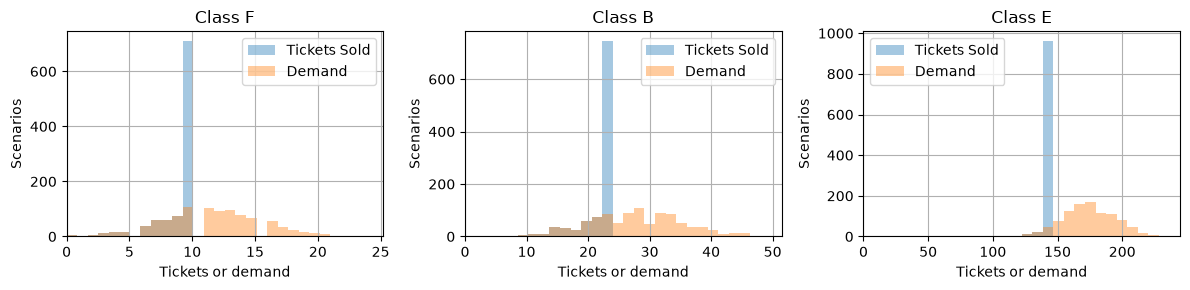

In [11]:
model_saa = aircraft_stochastic(demand_saa)
results = SOLVER.solve(model_saa)
pyo.assert_optimal_termination(results)
seats_saa = pd.Series({c: model_saa.seats[c]() for c in model_saa.CLASSES})
seat_report_saa(seats_saa, demand_saa)

Without service requirements, the expected revenue for given seats is

$$
\mathbb E[Q(\boldsymbol s,\boldsymbol z)]
=\sum_{c\in C}r_c\,\mathbb E[\min(s_c,z_c)].
$$

It therefore depends only on the marginal demand distributions. Correlation leaves the population optimization problems in Models 4 and 5 unchanged; differences between their sample results reflect sampling variation. Rounding each class's demand and replacing negative values by zero preserves this dependence on the marginals alone.

## Model 6. Tackling chance constraints using SAA in the case of correlated demand

The linear counterparts in Model 3 used independent normal demand. For jointly normal demand before rounding, the combined requirement still has a closed-form counterpart, now using the variance

$$
\operatorname{Var}(z_F+z_B)
=\sigma_F^2+\sigma_B^2+2\rho_{FB}\sigma_F\sigma_B.
$$

Positive first-/business-class correlation increases this variance and the seats needed for a given upper-tail service level. The sample-based formulation below does not rely on normality and uses the rounded, nonnegative samples directly.

This final model replaces the chance constraints by approximating them using two families of service constraints with separate violation budgets. In doing so, we introduce two new sets of binary variables $y_s$ and $w_s$ and scenario-specific big-M bounds and approximate the true multivariate distribution with the empirical one obtained from the sample. 

The first stage remains unchanged and so does the second-stage objective. The adjusted second-stage constraints are:

$$
\begin{align*}
    t_{c,s} & \leq s_c & \forall (c,s)\in C\times S \\
    t_{c,s} & \leq z_{c, s} & \forall (c, s) \in C \times S \\
    s_F + M_{F,s} y_s & \geq z_{F, s} & \forall s \in  S\\
    s_F + s_B + M_{FB,s} w_s & \geq z_{F, s} + z_{B,s} & \forall s \in  S \\
    \frac{1}{N} \sum_{s\in S} y_s & \leq 1 - 0.98 \\
    \frac{1}{N} \sum_{s\in S} w_s & \leq 1 - 0.95
\end{align*}
$$

where $y_s$ and $w_s$ are binary variables that permit a violation of the first-class and combined first-/business-class requirements in scenario $s$. A zero value enforces the corresponding requirement; a value of one permits a violation but need not imply one. The two budgets apply separately.

For the nonnegative sampled demands, we use $M_{F,s}=z_{F,s}$ and $M_{FB,s}=z_{F,s}+z_{B,s}$. These bounds fully relax the corresponding row when its indicator is one, since installed seat counts are nonnegative. A fixed $M$ chosen to deactivate every row for arbitrary nonnegative seat counts must be at least the largest sampled demand in each row. In the Cholesky sample here, these maxima are 24 for first class and 71 for combined first-/business-class demand, so 100 would suffice for this sample; the scenario-specific bounds avoid relying on that arbitrary constant. The empirical service rates reported below describe this sample; they are not an out-of-sample guarantee. 

The following cell implements this new model. Note that the running time for the cell can be up to a few minutes for a large number of scenarios.


Seat Allocation


,F,B,E,TOTAL
seat allocation,20.0,36.0,106.0,162.0
economy equivalent seat allocation,40.0,54.0,106.0,200.0



Mean Tickets Sold


F     11.549
B     27.145
E    106.000
dtype: float64


Mean Seats not Sold


F    8.451
B    8.855
E    0.000
dtype: float64


Mean Spillage (Unfulfilled Demand)


F     0.028
B     0.532
E    68.271
dtype: float64


Expected Revenue (in units of economy ticket price): 194.94


Sample first-class service: 98.4%
Sample combined service: 95.3%


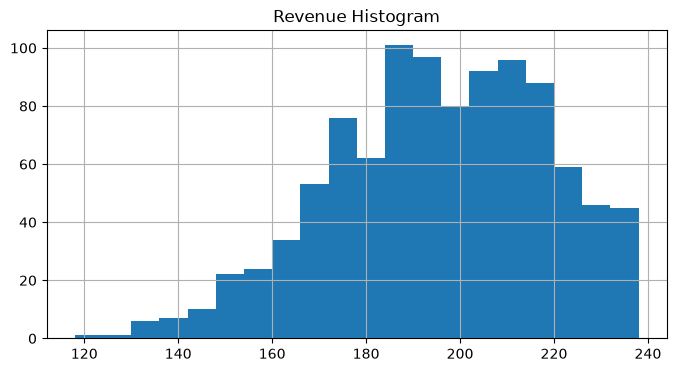

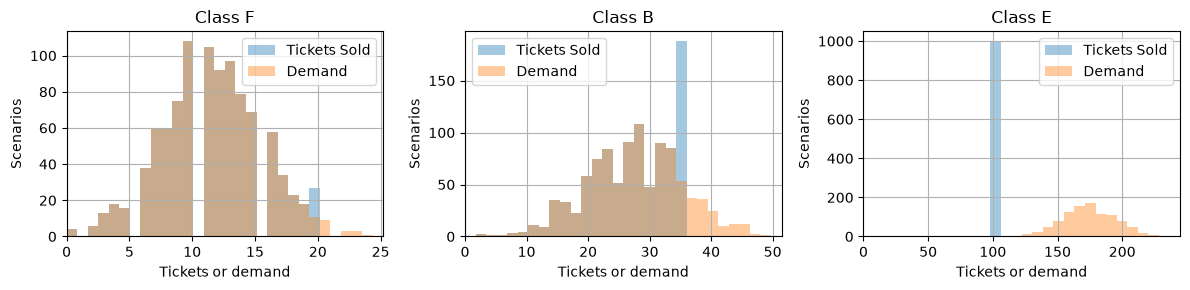

In [12]:
def aircraft_final(demand):
    m = pyo.ConcreteModel("Aircraft seat allocation - Correlated demand")

    m.CLASSES = pyo.Set(initialize=demand.columns)
    m.SCENARIOS = pyo.Set(initialize=demand.index)

    # first stage variables and constraints
    m.seats = pyo.Var(m.CLASSES, domain=pyo.NonNegativeIntegers)

    @m.Constraint()
    def plane_seats(m):
        return sum(m.seats[c] * seat_factor[c] for c in m.CLASSES) <= capacity

    # Scenario-specific bounds deactivate each service row completely.
    bigM_F = demand["F"]
    bigM_FB = demand["F"] + demand["B"]

    # second stage variable and constraints
    m.tickets = pyo.Var(m.CLASSES, m.SCENARIOS, domain=pyo.NonNegativeIntegers)
    m.first_class = pyo.Var(m.SCENARIOS, domain=pyo.Binary)
    m.business_class = pyo.Var(m.SCENARIOS, domain=pyo.Binary)

    @m.Constraint(m.CLASSES, m.SCENARIOS)
    def demand_limits(m, c, s):
        return m.tickets[c, s] <= demand[c][s]

    @m.Constraint(m.CLASSES, m.SCENARIOS)
    def seat_limits(m, c, s):
        return m.tickets[c, s] <= m.seats[c]

    @m.Constraint(m.SCENARIOS)
    def first_class_loyalty(m, s):
        return m.seats["F"] + bigM_F[s] * m.first_class[s] >= demand["F"][s]

    @m.Constraint()
    def first_class_loyalty_rate(m):
        return sum(m.first_class[s] for s in m.SCENARIOS) <= 0.02 * len(m.SCENARIOS)

    @m.Constraint(m.SCENARIOS)
    def business_class_loyalty(m, s):
        return (
            m.seats["F"] + m.seats["B"] + bigM_FB[s] * m.business_class[s]
            >= demand["B"][s] + demand["F"][s]
        )

    @m.Constraint()
    def business_class_loyalty_rate(m):
        return sum(m.business_class[s] for s in m.SCENARIOS) <= 0.05 * len(m.SCENARIOS)

    # objective
    @m.Objective(sense=pyo.maximize)
    def revenue(m):
        return sum(
            m.tickets[c, s] * revenue_factor[c] for c in m.CLASSES for s in m.SCENARIOS
        ) / len(m.SCENARIOS)

    return m


# create model
model = aircraft_final(demand_saa)
results = SOLVER.solve(model)
pyo.assert_optimal_termination(results)
seats = pd.Series({c: model.seats[c]() for c in model.CLASSES})
seat_report_saa(seats, demand_saa)

# Check the actual sample violations, independently of the indicator values.
first_violations = (demand_saa["F"] > seats["F"] + 1e-6).sum()
combined_violations = (
    demand_saa["F"] + demand_saa["B"] > seats["F"] + seats["B"] + 1e-6
).sum()
assert first_violations <= 0.02 * len(demand_saa) + 1e-6
assert combined_violations <= 0.05 * len(demand_saa) + 1e-6
print(f"Sample first-class service: {1 - first_violations / len(demand_saa):.1%}")
print(f"Sample combined service: {1 - combined_violations / len(demand_saa):.1%}")


**Exercise**

Solve Model 6 with $\rho_{FB}=-0.6$, $0$ and $0.6$, keeping $\rho_{FE}=0.2$ and $\rho_{BE}=0.4$. All three correlation matrices are positive definite. Repeat the comparison with several seeds, using Cholesky sampling. How do the combined first- and business-class seats and the sample expected revenue change? Explain the effect using the variance of $z_F+z_B$, and distinguish this service-level effect from sampling variation in Models 4 and 5.
